# Conformal prediction under distribution shift

Split conformal methods pool the last `n_windows` calibration errors and take one quantile of them. They
guarantee coverage *on average* when future errors look like past errors. When the error scale changes (a new
volatility regime, a surge), the pooled quantile reacts slowly because most calibration windows still describe the
old regime, and the coverage over any given stretch of time can be far from the target even though the average is close.

**Conformal PID control** ([Angelopoulos, Candes & Tibshirani, 2023](https://arxiv.org/abs/2307.16895)) replays the same
calibration windows in time order and *tracks* the error quantile online: a proportional step moves it after every
miss, and an integral term reacts to accumulated miscoverage. In `foundationforecast` it is a method object:
`ConformalIntervals(method=PID(...))`.

This notebook backtests it on a real series with changing volatility, **the GOOGL daily open price from 2008 to 2014**, in the spirit of the
stock experiments of the PID paper. We compare the intervals of the model itself, pooled conformal and PID. For the other
conformal methods see the [conformal prediction example](conformal-prediction.ipynb) and the
[conformal prediction guide](../conformal-prediction.md).

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"

## Import libraries

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from foundationforecast import PID, ConformalIntervals, FoundationForecast
from foundationforecast.models import Chronos


## Load the data

**Dataset:** the daily opening price of Google (GOOGL) from January 2006 to December 2014, in dollars of December 2014
(adjusted for the stock splits since then). Stock prices are the series the PID paper uses for its stock experiments (there,
the data come from a Kaggle collection of 30 blue-chip stocks). The prepared series is hosted on S3 with the standard columns `unique_id`,
`ds` and `y`.

The series is on the business-day calendar (`freq="B"`): the 82 market holidays of the period are filled with the previous open
(2,347 days in total), so the series has no gaps.

In [ ]:
df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/googl-daily-open.parquet"
)
len(df), df["ds"].min().date(), df["ds"].max().date()

(2347, datetime.date(2006, 1, 3), datetime.date(2014, 12, 31))

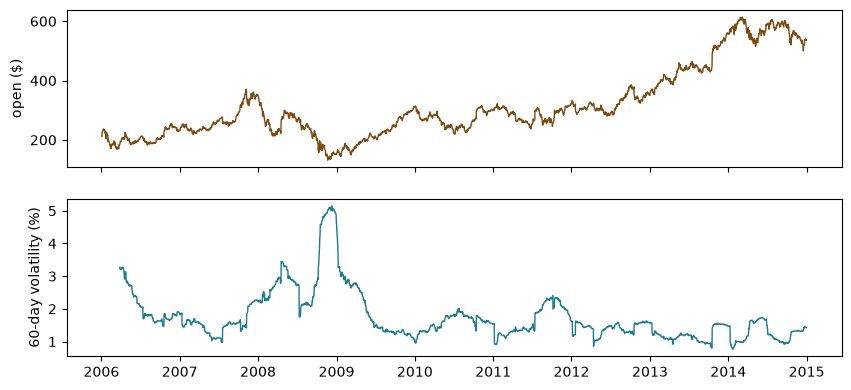

In [ ]:
returns = np.log(df["y"]).diff()
fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].plot(df["ds"], df["y"], color="#7b4a12", lw=1)
axes[0].set_ylabel("open ($)")
axes[1].plot(df["ds"], returns.rolling(60).std() * 100, color="#1f7a8c", lw=1)
axes[1].set_ylabel("60-day volatility (%)")
plt.show()

The 60-day volatility of the daily returns is about 1% to 2% most of the time but reaches 5% at the end of 2008, and rises again
in 2011 and 2014. A calibration window of one year taken after the 2008 crisis still describes that very volatile period, while one taken in a calm
year underestimates what comes next.

## Backtest setup

- **Point forecaster:** Chronos-Bolt small, one step ahead (`h=1`), with a rolling origin: the forecast of every day
  uses only the days before it.
- **Evaluation:** 2,000 one-step forecasts (`n_windows=2000`, `step_size=1`) from the spring of 2007 on. The first 250 are only used
  to calibrate, so the intervals are evaluated from 2008 to 2014 (about 1,750 days).
- **Target:** 80% intervals.
- **Calibration:** the last 250 one-step errors before each day (`n_windows=250`, `step_size=1`), a bit more than a trading year.
- **Three ways of getting the 80% interval from the same forecasts:**
  - **Chronos native:** the quantiles of the model itself (`level=[80]`, no calibration).
  - **`conformal_error`:** pooled split conformal on the absolute errors (the library default).
  - **`PID(symmetric=True)`:** conformal PID control on the absolute errors, with the default parameters. We use `symmetric=True`
    so that, like `conformal_error`, it uses one threshold on the absolute error.

One cross-validation run gives the point forecasts and the native intervals. The calibrated intervals of day \(t\) are what
`forecast()` would return with `ConformalIntervals` at that origin: it calibrates with the errors of the 250 previous days. Rerunning
the cross-validation of 250 windows for each of the 1,750 days would be wasteful, so we reuse the errors of the single run and
apply the same method objects.

In [ ]:
H, N_EVAL, N_CAL, LEVEL = 1, 2000, 250, 80

ff = FoundationForecast(models=[Chronos(repo_id="amazon/chronos-bolt-small", alias="chronos")])
cv = ff.cross_validation(
    df=df, h=H, n_windows=N_EVAL, step_size=1, freq="B", level=[LEVEL]
).reset_index(drop=True)
errors = (cv["y"] - cv["chronos"]).to_numpy()
cv[["ds", "y", "chronos", f"chronos-lo-{LEVEL}", f"chronos-hi-{LEVEL}"]].tail(3)

,ds,y,chronos,chronos-lo-80,chronos-hi-80
1997,2014-12-29,540.50,535.297546,520.484131,549.358643
1998,2014-12-30,534.96,540.098206,525.092957,553.921875
1999,2014-12-31,537.74,533.789062,519.005615,547.578491


In [ ]:
from foundationforecast.core.conformal import get_conformal_method  # what ConformalIntervals runs


def calibrated_intervals(ci, n_cal=N_CAL):
    """Interval of every day from the `n_cal` previous errors, as forecast() would compute it."""
    method = get_conformal_method(ci.method)
    lo, hi = [], []
    for t in range(N_CAL, N_EVAL):
        out = method(
            pd.DataFrame({"chronos": [cv["chronos"].iloc[t]]}),
            pd.DataFrame({"chronos": errors[t - n_cal : t]}),
            model_names=["chronos"],
            level=[LEVEL],
            cs_n_windows=n_cal,
            cs_h=H,
            n_series=1,
            horizon=H,
            step_size=1,
        )
        lo.append(out[f"chronos-lo-{LEVEL}"].iloc[0])
        hi.append(out[f"chronos-hi-{LEVEL}"].iloc[0])
    return np.array(lo), np.array(hi)


settings = {
    "conformal_error": ConformalIntervals(n_windows=N_CAL, step_size=1, method="conformal_error"),
    "PID": ConformalIntervals(n_windows=N_CAL, step_size=1, method=PID(symmetric=True)),
}
ev = cv.iloc[N_CAL:].reset_index(drop=True)
intervals = {
    "Chronos native": (ev[f"chronos-lo-{LEVEL}"].to_numpy(), ev[f"chronos-hi-{LEVEL}"].to_numpy()),
    **{name: calibrated_intervals(ci) for name, ci in settings.items()},
}

**Check against `forecast()`.** For the last day, the interval of the real `forecast()` call with `ConformalIntervals`
(it runs the 250-window cross-validation itself) is the same as the one we computed:

In [ ]:
train = df.iloc[:-1]
for name, ci in settings.items():
    model = Chronos(repo_id="amazon/chronos-bolt-small", alias="chronos", prediction_intervals=ci)
    fc = FoundationForecast(models=[model]).forecast(df=train, h=H, freq="B", level=[LEVEL])
    lo, hi = intervals[name][0][-1], intervals[name][1][-1]
    assert np.allclose([fc[f"chronos-lo-{LEVEL}"].iloc[0], fc[f"chronos-hi-{LEVEL}"].iloc[0]], [lo, hi])
    print(name, round(lo, 2), round(hi, 2))

conformal_error 524.08 543.5


PID 523.77 543.81


## Evaluation

For each method we report:

- **coverage:** the share of days in which the actual falls inside the 80% interval over the whole period.
- **min coverage (50d):** the lowest coverage in any 50-day stretch.
- **|local - 0.8|:** how far the 50-day rolling coverage is from the target on average. This is the number that matters for
  stability: a method can have 80% on average and still miss badly for months.
- **width:** the average width of the interval, in dollars.

In [ ]:
def summarize(intervals):
    rows = {}
    for name, (lo, hi) in intervals.items():
        covered = pd.Series(((ev["y"] >= lo) & (ev["y"] <= hi)).astype(float))
        local = covered.rolling(50).mean()
        rows[name] = {
            "coverage": covered.mean(),
            "min coverage (50d)": local.min(),
            "|local - 0.8|": (local - LEVEL / 100).abs().mean(),
            "width": (hi - lo).mean(),
        }
    return pd.DataFrame(rows).T


summarize(intervals).round(3)

,coverage,min coverage (50d),|local - 0.8|,width
Chronos native,0.889,0.70,0.100,18.871
conformal_error,0.790,0.50,0.087,12.843
PID,0.791,0.68,0.033,14.958


- **Chronos native** overcovers on average (0.889 for a target of 0.8) and its local coverage still swings (from 0.70 up to almost 1.0).
  The quantiles of the model are not calibrated for this series.
- **`conformal_error`** is on target on average (0.790), which is what its guarantee promises. But its local coverage goes down to 0.50,
  that is, in some 50-day stretch it misses half of the days when 20% are expected, and rises to 1.0 in others.
- **`PID`** stays close to the target throughout (lowest 50-day coverage 0.68, average deviation 0.033, roughly a third of the other two), with
  intervals 21% narrower than the native ones but 17% wider than `conformal_error`'s. You pay a wider interval for a more stable coverage.

The plot shows the 50-day rolling coverage over the whole period (top) and the series with the 80% set
(bottom). The sets are only about 3% to 5% of the price, so the boxes zoom on the two stretches where the rolling coverage of
`conformal_error` is lowest, found automatically, to make them visible.

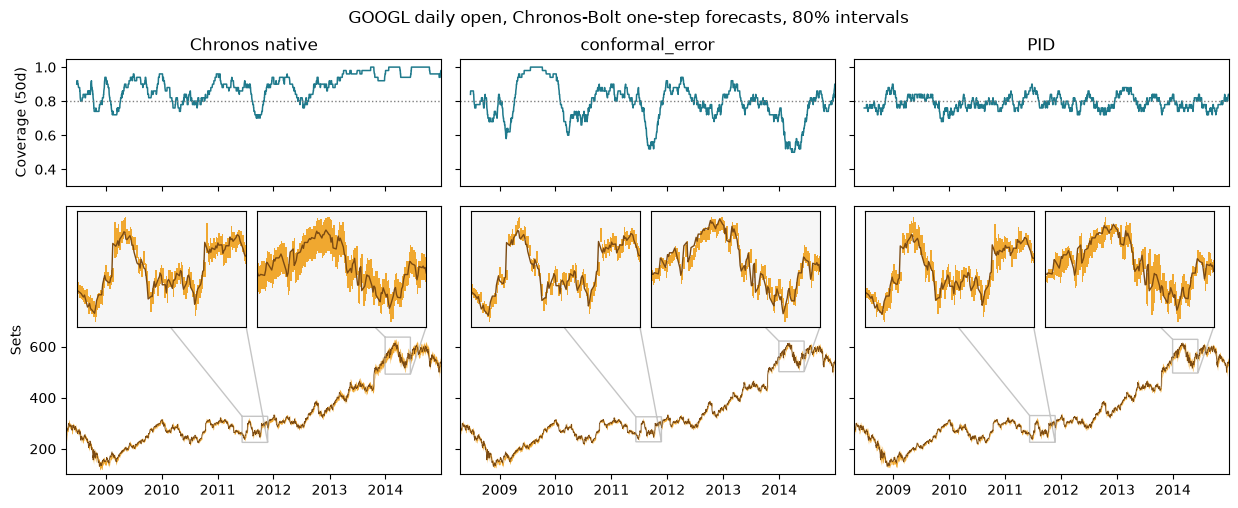

In [ ]:
x = ev["ds"]
cols = ["Chronos native", "conformal_error", "PID"]
local = {
    n: pd.Series(((ev["y"] >= lo) & (ev["y"] <= hi)).astype(float)).rolling(50).mean()
    for n, (lo, hi) in intervals.items()
}

# windows of +-60 days around the two lowest points of conformal_error's rolling coverage
r = local["conformal_error"].copy()
centers = []
for _ in range(2):
    i = int(r.idxmin())
    centers.append(i)
    r.iloc[max(0, i - 200) : i + 200] = np.inf
zooms = [(max(0, i - 60), min(len(ev), i + 60)) for i in sorted(centers)]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 5.4), sharex=True,
    gridspec_kw={"height_ratios": [1, 2.1], "hspace": 0.1, "wspace": 0.05},
)
for c, name in enumerate(cols):
    lo, hi = intervals[name]
    ax = axes[0, c]
    ax.plot(x, local[name], color="#1f7a8c", lw=1.1)
    ax.axhline(LEVEL / 100, color="gray", ls=":", lw=1)
    ax.set_ylim(0.3, 1.05)
    ax.set_title(name)
    ax = axes[1, c]
    ax.fill_between(x, lo, hi, color="#f0a830", lw=0)
    ax.plot(x, ev["y"], color="#7b4a12", lw=0.6)
    ax.set_xlim(x.iloc[0], x.iloc[-1])
    ax.set_ylim(100, 1150)
    ax.set_yticks([200, 400, 600])
    for k, (a, b) in enumerate(zooms):
        ins = ax.inset_axes([0.03 + 0.48 * k, 0.55, 0.45, 0.43])
        s = slice(a, b)
        ins.fill_between(x[s], lo[s], hi[s], color="#f0a830", lw=0, step="mid")
        ins.plot(x[s], ev["y"][s], color="#7b4a12", lw=1)
        both = np.r_[lo[s], hi[s], ev["y"][s]]
        pad = 0.05 * (both.max() - both.min())
        ins.set_xlim(x.iloc[a], x.iloc[b - 1])
        ins.set_ylim(both.min() - pad, both.max() + pad)
        ins.set_xticks([])
        ins.set_yticks([])
        ins.set_facecolor("#f6f6f6")
        ax.indicate_inset_zoom(ins, edgecolor="0.55")
    if c == 0:
        axes[0, c].set_ylabel("Coverage (50d)")
        ax.set_ylabel("Sets")
    else:
        axes[0, c].tick_params(labelleft=False)
        ax.tick_params(labelleft=False)
fig.suptitle("GOOGL daily open, Chronos-Bolt one-step forecasts, 80% intervals", y=0.97)
plt.show()

- **Top:** the coverage of `conformal_error` oscillates widely. It stays near 1.0 in 2009, when the calibration window still contains the 2008 crisis and the sets are too wide, and
  drops in 2011 and 2014, when volatility rises and the sets calibrated on calmer months are too narrow. `PID` hovers around 0.8.
- **Zooms:** in both stretches the `conformal_error` set barely changes while the price moves up and down; the `PID` set widens with the moves and
  narrows again afterwards. The native set is wide in both.
- The two zoomed stretches are the two lowest points of `conformal_error`, so they show the worst case of that method, not a typical period. The top row and the table cover all the days.

**Does it depend on the calibration window?** `conformal_error` uses the last `n_windows` errors, so the choice matters. Here is the
same comparison with 30, 100 and 250 windows, evaluated on the same days. We add `PID(symmetric=True, integrate=False)`, i.e.
quantile tracking only, to see what the integrator adds.

In [ ]:
rows = {}
for n_cal in [30, 100, 250]:
    for name, method in {
        "conformal_error": "conformal_error",
        "PID": PID(symmetric=True),
        "PID (no integrator)": PID(symmetric=True, integrate=False),
    }.items():
        ci = ConformalIntervals(n_windows=n_cal, step_size=1, method=method)
        rows[(n_cal, name)] = summarize({name: calibrated_intervals(ci, n_cal)}).iloc[0]
pd.DataFrame(rows).T.rename_axis(["n_windows", "method"]).round(3)

coverage  min coverage (50d)  |local - 0.8|  \
n_windows method                                                             
30        conformal_error         0.780                0.60          0.044   
          PID                     0.799                0.66          0.037   
          PID (no integrator)     0.788                0.68          0.033   
100       conformal_error         0.786                0.54          0.074   
          PID                     0.809                0.66          0.038   
          PID (no integrator)     0.801                0.70          0.029   
250       conformal_error         0.790                0.50          0.087   
          PID                     0.791                0.68          0.033   
          PID (no integrator)     0.803                0.68          0.028   

                                width  
n_windows method                       
30        conformal_error      12.667  
          PID                  15.648  
          PID (no integrator)  13.252  
100       conformal_error      12.870  
          PID                  15.256  
          PID (no integrator)  13.895  
250       conformal_error      12.843  
          PID                  14.958  
          PID (no integrator)  14.176

- **Pooled conformal depends on the window.** The deviation of `conformal_error` grows with the number of windows (0.044, 0.074, 0.087) and its worst
  50-day coverage falls from 0.60 to 0.50: the longer the memory, the slower it reacts. With 30 windows it is already close to `PID` (0.044 against 0.037).
- **`PID` is stable across windows** (0.037, 0.038, 0.033), so you do not have to tune the length of the calibration history for it.
- **The integrator does not help here.** `PID (no integrator)` has a lower deviation than the full `PID` at every window length and
  narrower intervals (for example 14.2 against 15.0 with 250 windows). What improves the coverage on this series is the quantile tracking.
  Check both variants on your own data.
- This is one series and one model with a one-step horizon: it shows that the effect exists and when it appears (a long calibration window and changing volatility), not
  that `PID` always beats pooled conformal.

## When to use PID

Use `PID()` when the error scale of your series can change between the calibration period and the forecast
period and a loss of coverage is costlier than wider intervals: volatility regimes, epidemic waves, demand shocks.
Stay with the pooled methods when errors are stable and you want the tightest intervals.

- `PID(integrate=False)` gives tighter intervals. Here it does as well as the full `PID`; compare both on your own data.
- `PID(symmetric=True)` tracks absolute errors with one threshold instead of separate lower and upper tails.
- **Calibration windows matter.** With overlapping windows (`step_size` smaller than `h`) neighbouring errors are strongly
  correlated and the integrator can saturate, which makes some bounds infinite and `forecast()` emits a `UserWarning`: use more
  or non-overlapping windows, raise `Csat` or `Tg`, or set `integrate=False`.
- Check the achieved coverage and interval width on your own backtest, as done here.

See the [conformal prediction guide](../conformal-prediction.md#conformal-pid-control-under-distribution-shift) for the
update rule, every `PID` parameter, the delayed-feedback handling and the R cross-check.